### 1. Inicijalizacija okruženja i bezbedno povezivanje na bazu podataka

- **Konfiguracija okruženja i bezbednost:** Osetljivi parametri konekcije (IP adresa udaljenog servera, korisničko ime i lozinka) uspešno su izdvojeni u lokalni sistemski `.env` fajl. Time su ispunjeni standardi bezbednosti softverskog razvoja, a baza je zaštićena od javnog eksponiranja na GitHub repozitorijumu (kroz `.gitignore` mehanizam i prateći `.env.template` šablon).

- **Dinamičko učitavanje parametara:** Upotrebom biblioteka `python-dotenv` (`load_dotenv` i `find_dotenv`), konfiguracione promenljive se bezbedno učitavaju u radno okruženje bez obzira na trenutnu putanju izvršavanja Jupyter sveske.

- **Uspostavljanje konekcije i inspekcija šeme:** Korišćenjem `SQLAlchemy` biblioteke (`create_engine`) ostvarena je stabilna i sigurna veza sa PostgreSQL serverom preko virtuelne privatne mreže (`xxx.xxx.xxx.xxx`). Pomoću modula `inspect` verifikovana je struktura baze i potvrđeno prisustvo svih ključnih produkcionih tabela, sa posebnim akcentom na centralnu tabelu `istorija_cena`.

In [7]:
import os
import pandas as pd
from sqlalchemy import create_engine, inspect
from dotenv import load_dotenv, find_dotenv

# Pronalazi i učitava .env fajl bez obzira na radni direktorijum kernela
load_dotenv(find_dotenv(), override=True)

IP_SERVERA = os.getenv("DB_HOST")
KORISNIK = os.getenv("DB_USER")
LOZINKA = os.getenv("DB_PASSWORD")
IME_BAZE = os.getenv("DB_NAME")

# Provera da li su promenljive uspešno učitane pre pravljenja konekcije
assert IP_SERVERA is not None, "Greška: DB_HOST nije učitan iz .env fajla!"
assert LOZINKA is not None, "Greška: DB_PASSWORD nije učitan iz .env fajla!"

url = f"postgresql+psycopg2://{KORISNIK}:{LOZINKA}@{IP_SERVERA}:5432/{IME_BAZE}"

try:
    engine = create_engine(url)
    inspector = inspect(engine)
    tabele = inspector.get_table_names()
    
    print("USPEŠNA KONEKCIJA PREKO .env FAJLA!")
    print("Tabele u bazi:")
    print("-" * 30)
    for t in tabele:
        print(f" -> {t}")
        
except Exception as e:
    print("GREŠKA PRI POVEZIVANJU:")
    print(e)

USPEŠNA KONEKCIJA PREKO .env FAJLA!
Tabele u bazi:
------------------------------
 -> belex_ticker_live
 -> istorija_indeksa
 -> system_logs
 -> tabela_tickera
 -> istorija_cena
 -> arhiva_vesti
 -> users
 -> user_subscriptions
 -> email_queue


### 2. Preuzimanje, predobrada podataka i vizuelizacija korelacija

- **Učitavanje izvornog skupa podataka:** Izvršen je SQL upit nad tabelom `istorija_cena` kojim je u radnu memoriju Pandas `DataFrame`-a uspešno preuzeto ukupno **192.644 istorijska zapisa** kretanja cena i obima na Beogradskoj berzi.

- **Filtriranje i čišćenje niske likvidnosti:** U skladu sa definisanom metodologijom za rad sa domaćim tržištem hartija od vrednosti, primenjen je filter za eliminaciju zapisa sa nultim obimom trgovanja (`obim > 0`), čime je izdvojen relevantan analitički podskup od **41.350 validnih opservacija**.

- **Statistička analiza korelacije:** Izračunate su Pearsonova i Spearmanova korelaciona matrica nad odabranim numeričkim obeležjima (`cena`, `obim`, `promet`, `vwap`, `cena_otvaranja`, `najvisa_dnevna`, `najniza_dnevna`).

- **Vizuelizacija multikolinearnosti:** Pomoću biblioteka `seaborn` i `matplotlib` generisana je toplotna mapa (*heatmap*) korelacija sa označenim koeficijentima, čime je obezbeđen vizuelni artefakt za četvrto poglavlje seminarskog rada i utvrđen stepen međusobne zavisnosti atributa pre primene modela mašinskog učenja.

Ukupno učitano redova: 192644
Broj redova nakon uklanjanja nultih obima: 41350

--- Pearsonova korelaciona matrica ---


,cena,obim,promet,vwap,cena_otvaranja,najvisa_dnevna,najniza_dnevna
cena,1.000000,-0.240703,0.356218,1.000000,0.999997,0.999999,0.999996
obim,-0.240703,1.000000,0.564297,-0.240703,-0.240139,-0.240223,-0.240952
promet,0.356218,0.564297,1.000000,0.356218,0.356305,0.356506,0.356004
vwap,1.000000,-0.240703,0.356218,1.000000,0.999997,0.999999,0.999996
cena_otvaranja,0.999997,-0.240139,0.356305,0.999997,1.000000,0.999997,0.999993
najvisa_dnevna,0.999999,-0.240223,0.356506,0.999999,0.999997,1.000000,0.999991
najniza_dnevna,0.999996,-0.240952,0.356004,0.999996,0.999993,0.999991,1.000000



--- Spearmanova korelaciona matrica ---


,cena,obim,promet,vwap,cena_otvaranja,najvisa_dnevna,najniza_dnevna
cena,1.000000,-0.573986,-0.050753,1.000000,0.994303,0.997896,0.995471
obim,-0.573986,1.000000,0.778267,-0.573986,-0.571556,-0.563783,-0.581184
promet,-0.050753,0.778267,1.000000,-0.050753,-0.049832,-0.039427,-0.058665
vwap,1.000000,-0.573986,-0.050753,1.000000,0.994303,0.997896,0.995471
cena_otvaranja,0.994303,-0.571556,-0.049832,0.994303,1.000000,0.994910,0.997864
najvisa_dnevna,0.997896,-0.563783,-0.039427,0.997896,0.994910,1.000000,0.993039
najniza_dnevna,0.995471,-0.581184,-0.058665,0.995471,0.997864,0.993039,1.000000


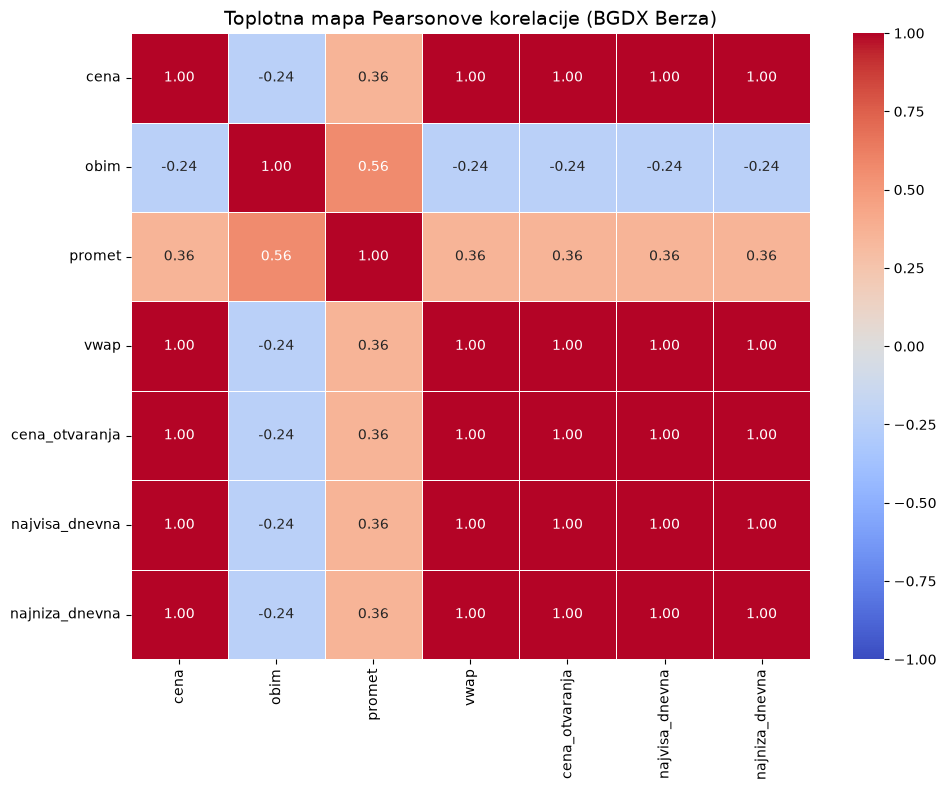

In [ ]:
import pandas as pd
import seaborn as sbn
import matplotlib.pyplot as plt

# 1. Učitavanje izvornog skupa podataka iz baze
query = """
SELECT ticker, vreme, cena, obim, promet, vwap, cena_otvaranja, najvisa_dnevna, najniza_dnevna 
FROM istorija_cena;
"""
df = pd.read_sql(query, con=engine)
print(f"Ukupno učitano redova: {df.shape[0]}")

# 2. Filtriranje i čišćenje niske likvidnosti (uklanjanje nultih obima)
df_validno = df[(df['obim'] > 0) & (df['obim'].notna())]
print(f"Broj redova nakon uklanjanja nultih obima: {df_validno.shape[0]}")

# 3. Statistička analiza korelacije (Pearson i Spearman)
numericke_kolone = ['cena', 'obim', 'promet', 'vwap', 'cena_otvaranja', 'najvisa_dnevna', 'najniza_dnevna']

pearson_corr = df_validno[numericke_kolone].corr(method='pearson')
spearman_corr = df_validno[numericke_kolone].corr(method='spearman')

print("\n--- Pearsonova korelaciona matrica ---")
display(pearson_corr)

print("\n--- Spearmanova korelaciona matrica ---")
display(spearman_corr)

# 4. Vizuelizacija multikolinearnosti (Toplotna mapa / Heatmap)
plt.figure(figsize=(10, 8))
sbn.heatmap(pearson_corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Toplotna mapa Pearsonove korelacije (BGDX Berza)", fontsize=14)
plt.tight_layout()
plt.show()